In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} /content/{repo_name}
    os.chdir(f"/content/{repo_name}/2")
    sys.path.insert(0, f"/content/{repo_name}")
    !pip install -q -r /content/{repo_name}/requirements.txt
    !pip install -q -e /content/{repo_name}
    print("環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    proj_root = Path.cwd().resolve()
    if proj_root.name == "2":
        proj_root = proj_root.parent
    if str(proj_root) not in sys.path:
        sys.path.insert(0, str(proj_root))
    print("ローカル実行環境を検出しました。プロジェクトルート:", proj_root)


ローカル実行環境を検出しました。プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 2.8 ポインタ入門(1)：アドレスとポインタ (`Pointers Part 1: Address and Pointer`)

本節では、名著『**ゼロからのOS自作入門**』第2章「EDK II入門とメモリマップ」の後半における最重要理論トピックである **「ポインタ（Pointer）とアドレス（Address）」** の基礎構造を徹底解剖します。

OS自作や低レイヤプログラミングにおいて、ポインタは単なる「C/C++の難解な文法」ではありません。
**CPUがメインメモリ（RAM）、フレームバッファ（VRAM）、PCIデバイスの制御レジスタ（MMIO: Memory-Mapped I/O）といったハードウェアを直接制御するための唯一の物理的アクセス手段** です。

2.5節・2.6節で `GetMemoryMap` や `SaveMemoryMap` を実装した際、可変長ディスクリプタを走査するために `(uintptr_t)buffer + iter` や `reinterpret_cast<EFI_MEMORY_DESCRIPTOR*>` という高度なポインタ操作が登場しました。
本節では、64ビット（x86-64）アーキテクチャのメモリモデル、アドレス演算子 `&`、間接参照演算子 `*`、リトルエンディアンバイト配置、ポインタ算術（Pointer Arithmetic）の数理的スケーリング、そしてOS開発における型キャストの必然性を完全自己完結で解き明かします。

## 2.8.1 なぜ OS 自作・低レイヤ制御でポインタが不可欠なのか？（動機と課題）

### 高級言語のメモリ抽象化 vs OSカーネルのベアメタル制御
Python, Java, Go, Rust などの現代の高級プログラミング言語では、変数のメモリ配置やアドレスは実行時環境（ランタイム）やガベージコレクタ（GC）、コンパイラの所有権システムによって厳密に隠蔽・抽象化されています。
通常のアプリケーション開発者が「この変数の物理番地は `0x1000` である」といったアドレスを意識する必要は一切ありません。

しかし、私たちが作っているのは **その抽象化を提供する土台そのものである OS カーネル** です。
OSカーネルやブートローダ（UEFI）が動作するベアメタル（Bare Metal: 生のハードウェア）環境では、以下のような事象が日常的に発生します：

1. **画面にピクセルを描画したい（第3章・第4章）**:
   - ディスプレイコントローラ（GPU）のフレームバッファ（VRAM: *Video RAM*）は、PCIバス経由で特定の物理アドレス（例: `0xE0000000` など）にマッピング（MMIO: *Memory-Mapped I/O*）されています。
   - 画面の座標 $(x, y)$ を白く光らせるには、その物理アドレスをポインタとして解釈し、直接 32ビットの RGB 値（`0x00FFFFFF`）をメモリに書き込む（Store）しかありません。
2. **ブートローダからカーネルへ実行権をジャンプさせたい（第3章）**:
   - ディスクからメモリ上の `0x100000`（1MiB番地）に読み込んだカーネルの機械語コードを実行するには、アドレス `0x100000` を **関数ポインタ（Function Pointer）** にキャストして呼び出す必要があります。
3. **UEFI メモリマップの可変長配列を走査したい（2.5節・2.6節）**:
   - ファームウェアから返されるメモリディスクリプタ配列は、エントリのサイズ（`DescriptorSize`）が実行時まで未定です。
   - 正確に次のエントリへ進むためには、アドレスの数値をバイト単位で加算するポインタ演算が不可欠でした。

> [!IMPORTANT]
> **ポインタの本質**: ポインタとは、**「ハードウェアの特定の物理メモリ番地（または仮想メモリ番地）を指し示し、CPUのメモリ読み書き命令（`MOV` 命令）を発行するための道具」** です。

## 2.8.2 メモリの構造とアドレス（1バイトごとの小部屋と 64-bit アドレス空間）

### メモリは「1バイトごとに番号が付いた巨大なバイト配列」
コンピュータのメインメモリ（DRAM）は、物理的には極めてシンプルな構造をしています。
メモリは **「1バイト（8ビット = 0〜255）のデータを格納できる小部屋（Memory Cell）が一列に並んだ巨大なバイト配列」** とみなすことができます。

各小部屋には、先頭から `0, 1, 2, 3, ...` と連番の整数が割り振られています。
この **小部屋の番号（インデックス）こそが「アドレス（Address）」** です。

```text
【メモリ空間の概念モデル: 1バイトごとの配列】
+-----------+-----------+-----------+-----------+-----------+-----------+
| Address   |  0x1000   |  0x1001   |  0x1002   |  0x1003   |  0x1004   | ...
+-----------+-----------+-----------+-----------+-----------+-----------+
| Data (1B) |   0x78    |   0x56    |   0x34    |   0x12    |   0x00    | ...
+-----------+-----------+-----------+-----------+-----------+-----------+
```

### 64ビット（x86-64）アーキテクチャにおけるアドレスの幅
CPUのアーキテクチャ（32ビット vs 64ビット）は、主に **「アドレスを表現するレジスタのビット幅」** によって定義されます。

- **32ビットアーキテクチャ（IA-32 / x86）**:
  - アドレス幅: 32ビット（4バイト）
  - 最大指定可能アドレス: $2^{32} = 4,294,967,296\,\text{バイト} = 4\,\text{GiB}$
  - メインメモリが 4GiB 以上搭載されていても、32ビットアドレスでは直接指し示すことができません（PAE等の拡張が必要）。
- **64ビットアーキテクチャ（x86-64 / AMD64）**:
  - アドレス幅: 64ビット（8バイト）
  - 理論上の最大アドレス: $2^{64} = 18,446,744,073,709,551,616\,\text{バイト} \approx 16\,\text{EiB}$（エクサバイト）
  - 現代のプロセッサ（Intel Core / AMD Ryzen 等）の実装では、ページング回路の配線コストの都合上、下位 48ビット（$2^{48} = 256\,\text{TiB}$）を正規アドレス（Canonical Address）として利用します（第19章で詳述）。

したがって、**64ビットOS（MikanOS）において、すべてのアドレスは「64ビットの符号なし整数（`uint64_t` / `uintptr_t`）」として表現されます**。

## 2.8.3 変数とアドレス・アドレス演算子 `&`（Address-of Operator）

### 変数とは「メモリ上の領域に付けた人間に分かりやすいラベル」
プログラム中で `int a = 0x12345678;` のように変数を宣言すると、コンパイラはメモリ上の空いている連続領域に `a` の領域を割り当てます。
CPUにとっては変数名 `a` などという文字列は存在せず、**「ある先頭アドレスから始まる $N$ バイトの領域」** として認識されます。

各基本データ型が占有するバイトサイズ（Size in Bytes）：

| 型 (C/C++ Type) | 占有サイズ (sizeof) | 表現可能な値の範囲 |
|---|:---:|---|
| `char` / `int8_t` / `uint8_t` | **1 バイト** (8 bit) | $-128 \sim 127$ / $0 \sim 255$ |
| `short` / `int16_t` / `uint16_t` | **2 バイト** (16 bit) | $-32,768 \sim 32,767$ / $0 \sim 65,535$ |
| `int` / `int32_t` / `uint32_t` | **4 バイト** (32 bit) | 約 $-21.4$ 億 $\sim +21.4$ 億 / 約 $0 \sim 42.9$ 億 |
| `long long` / `int64_t` / `uint64_t` | **8 バイト** (64 bit) | 約 $-9.22 \times 10^{18} \sim +9.22 \times 10^{18}$ |
| ポインタ全種 (`T*`, `void*`) | **8 バイト** (64 bit) | 64ビットアドレス全域 (`0x0` 〜 `0xFFFFFFFFFFFFFFFF`) |

### アドレス演算子 `&`（Address-of Operator）
変数がメモリ上の何番地に配置されたのかを調べる演算子が **アドレス演算子 `&`** です。
例えば、`&a` と書くと、変数 `a` の占有領域の **「先頭バイトのアドレス（64ビット整数値）」** が得られます。

### x86-64 のリトルエンディアン（Little-Endian）バイト配置
x86-64 プロセッサは **リトルエンディアン（Little-Endian）** 方式を採用しています。
複数バイトにまたがる整数値（例: 4バイトの `0x12345678`）をメモリに書き込む際、**「最下位バイト（LSB: Least Significant Byte）を最も若いアドレス（低位番地）に配置する」** というルールです。

```text
値: 0x12345678 (32-bit uint32_t)
最下位バイト (LSB) = 0x78, 最上位バイト (MSB) = 0x12

メモリ配置先頭アドレスが 0x1000 の場合:
  0x1000 (+0): 0x78  <-- LSB が先頭！
  0x1001 (+1): 0x56
  0x1002 (+2): 0x34
  0x1003 (+3): 0x12  <-- MSB が最後
```
このバイト配置を理解していないと、メモリダンプ（Hex Dump）を見ても値が逆順に見えてしまい、低レイヤデバッグで大きな混乱を招きます。

## 2.8.4 ポインタ変数と 64-bit アーキテクチャのサイズ不変性

### ポインタ変数とは？
ポインタ変数（Pointer Variable）とは、**「他の変数やハードウェア領域のメモリアドレス（番地）を値として格納するための変数」** です。

```cpp
int val = 0x12345678;  // 4バイトの整数変数
int* ptr = &val;       // val のメモリアドレスを格納するポインタ変数 ptr
```

### 【超重要】64ビット環境におけるポインタのサイズ不変性
プログラミング初心者が抱きがちな典型的な誤解に、
「`char*` は 1バイトの変数を指すからポインタも 1バイトで、`int*` は 4バイト、巨大な `struct LargeStruct*` は巨大なのでは？」
というものがあります。

これは **完全に誤り** です！
ポインタ変数に格納されるのは、あくまで **「64ビットのメモリアドレスという数値」** そのものです。
指し示す先（Pointee）が 1バイトの `char` であろうと、40バイトの `EFI_MEMORY_DESCRIPTOR` であろうと、10メガバイトの配列であろうと、**メモリアドレス自体の幅は常に 64ビット（8バイト）** です。

```cpp
static_assert(sizeof(char*) == 8);
static_assert(sizeof(int*) == 8);
static_assert(sizeof(double*) == 8);
static_assert(sizeof(EFI_MEMORY_DESCRIPTOR*) == 8);
static_assert(sizeof(void*) == 8);
```
この「ポインタ自身のサイズは常に 8バイト固定」という原則は、構造体のパディング計算やアライメント、システムコールの引数渡しにおいて極めて重要です。

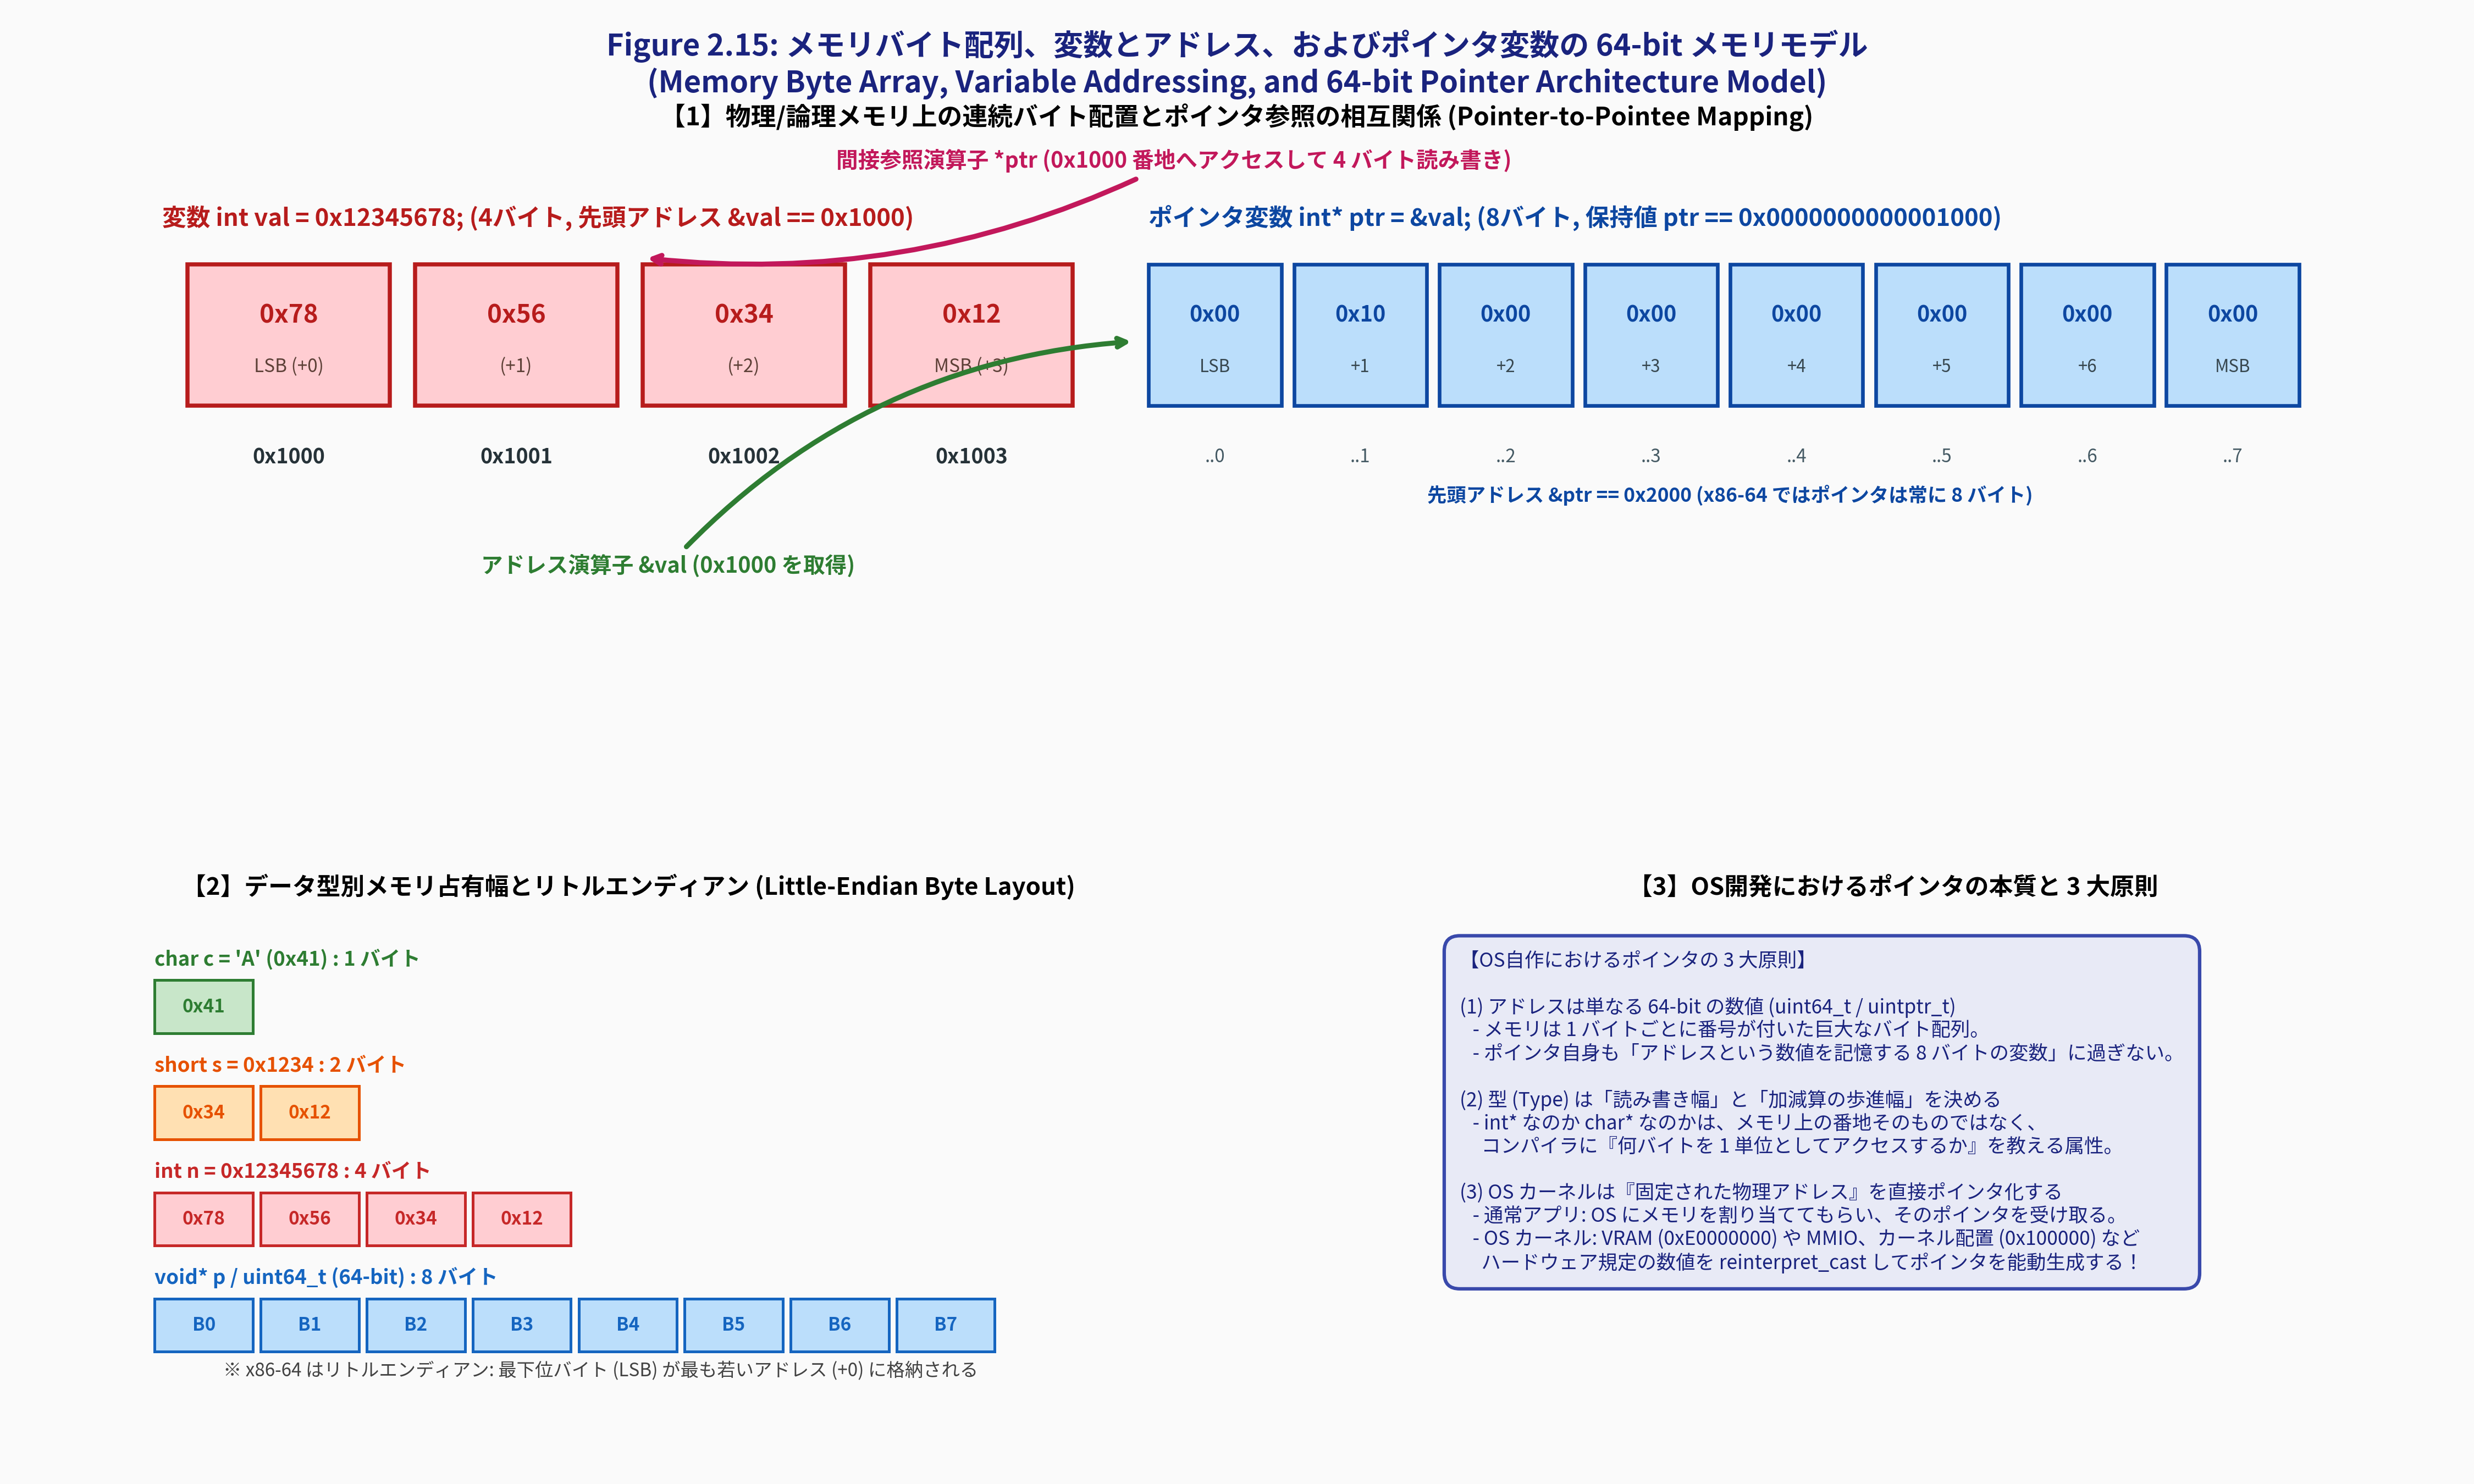

In [2]:
# 高解像度図版 Figure 2.15 の生成とインライン表示
from common import plot_figure_2_15_pointer_memory_model
from IPython.display import Image, display

fig2_15_path = "result/fig2_15_pointer_memory_model_and_address.png"
plot_figure_2_15_pointer_memory_model(fig2_15_path)
display(Image(filename=fig2_15_path, width=950))


## 2.8.5 間接参照演算子 `*`（デリファレンス / Dereference Operator）

### ポインタが指す先を読み書きする `*` 演算子
ポインタ変数 `ptr` が保持しているアドレスの場所へ行き、そのメモリ領域を読み取ったり書き換えたりする操作を **間接参照（デリファレンス: Dereference）** と呼び、アスタリスク `*` 演算子を使用します。

```cpp
int val = 100;
int* ptr = &val;

// 1. 間接参照による読み出し (Load)
int x = *ptr;   // ptr が保持するアドレス (val の番地) から 4 バイト読み出して x に代入 (x == 100)

// 2. 間接参照による書き込み (Store)
*ptr = 999;     // ptr が保持するアドレスのメモリに 4 バイトの数値 999 を書き込む
// この結果、val の値自身が 999 に書き換わる！
```

### x86-64 アセンブリ命令レベルでの動作
間接参照演算子 `*` は、CPUの機械語レベルでは **「レジスタ間接アドレッシング（Register Indirect Addressing）」** 命令に直接コンパイルされます。

```nasm
; RDI レジスタにポインタ変数 ptr の値 (メモリアドレス 0x1000) が入っているとする

; 読み出し: int x = *ptr;
mov eax, [rdi]        ; RDI が指すアドレスから 4バイト (DWORD) 読み出して EAX に格納

; 書き込み: *ptr = 999;
mov dword ptr [rdi], 999 ; RDI が指すアドレスに 4バイトの即値 999 をストア
```

角括弧 `[...]` は「そのレジスタの数値をメモリアドレスとみなしてアクセスせよ」という意味です。
C/C++ の `*ptr` は、まさにアセンブリの `[reg]` と 1対1 に対応していることが分かります。

### アドレス演算子 `&` と間接参照演算子 `*` の逆演算関係
- `&` は「変数からアドレスを取り出す操作」（型 `T` $\to$ 型 `T*`）
- `*` は「アドレスから変数の実体へアクセスする操作」（型 `T*` $\to$ 型 `T`）

したがって、任意の変数 `x` に対して `*(&x)` は `x` そのものに一致します。

## 2.8.6 ポインタの型と役割：なぜ `void*` だけでは不十分なのか？

アドレス自体は単なる 64ビットの数値に過ぎません。
では、なぜ C/C++ では単一の「アドレス型（`void*` のようなもの）」だけではなく、`int*` や `char*` や `uint64_t*` といった **「指す対象の型を明記したポインタ型」** が厳格に区別されているのでしょうか？

その理由は決定的な **2つの物理的役割** があるからです：

### 役割 1: デリファレンス時のアクセス幅（Access Width）の決定
メモリ上のあるアドレス `0x1000` を指しているとき、CPUはその番地から **「何バイト読み取るべきか」** を知る必要があります。
- `char* p`: `*p` は **1 バイト**（`mov al, byte ptr [rdi]`）を読み書きする。
- `short* p`: `*p` は **2 バイト**（`mov ax, word ptr [rdi]`）を読み書きする。
- `int* p`: `*p` は **4 バイト**（`mov eax, dword ptr [rdi]`）を読み書きする。
- `uint64_t* p`: `*p` は **8 バイト**（`mov rax, qword ptr [rdi]`）を読み書きする。

もし型情報のない `void*` の場合、何バイト読み取ればよいか判断できないため、C/C++ では `*void_ptr` のようなデリファレンスはコンパイルエラーとなります。

### 役割 2: ポインタ加減算における歩進ステップ幅（Stride）の決定
次項で解説する「ポインタ算術（Pointer Arithmetic）」において、ポインタを `+1` したときにアドレスが何バイト進むかを決めるのがポインタの型です。

## 2.8.7 ポインタ算術（Pointer Arithmetic）の数理導出と MikanOS の落とし穴

### ポインタ加減算の数理モデル
C/C++ におけるポインタの加算 `p + n` は、**単純なアドレスの数値加算ではありません**。
コンパイラは自動的に、指している型 `T` のサイズ `sizeof(T)` を掛け算してアドレスを進めます。

$$\text{Address}(p + n) = \text{Address}(p) + n \times \text{sizeof}(*p)$$

| ポインタの宣言 | 型サイズ `sizeof(*p)` | `p + 1` の進み幅 | `p + 2` の進み幅 |
|---|:---:|:---:|:---:|
| `char* p = (char*)0x1000;` | 1 バイト | `0x1001` (+1B) | `0x1002` (+2B) |
| `short* p = (short*)0x1000;` | 2 バイト | `0x1002` (+2B) | `0x1004` (+4B) |
| `int* p = (int*)0x1000;` | 4 バイト | `0x1004` (+4B) | `0x1008` (+8B) |
| `uint64_t* p = (uint64_t*)0x1000;` | 8 バイト | `0x1008` (+8B) | `0x1010` (+16B) |
| `EFI_MEMORY_DESCRIPTOR* p` | 48 バイト | `0x1030` (+48B) | `0x1060` (+96B) |

配列 `int a[5];` において `a[i]` が `*(a + i)` と等価であるのは、まさにこの数理スケーリングのおかげです。

---

### MikanOS 第2章の核心・落とし穴（メモリマップ走査の罠）
2.5節・2.6節で学習した UEFI メモリマップの走査コードを思い出してください。
UEFI の `GetMemoryMap()` が返すメモリマップバッファ内では、各ディスクリプタは `descriptor_size` バイト（典型的には 48 バイト）ごとに並んでいます。

ここで、初心者がやってしまいがちな **致命的なバグ** が以下のコードです：

```cpp
// 致命的な誤りコード
EFI_MEMORY_DESCRIPTOR* desc = (EFI_MEMORY_DESCRIPTOR*)buffer;
desc += descriptor_size;  // descriptor_size は 48
```

何が起きるでしょうか？
`desc` は `EFI_MEMORY_DESCRIPTOR*` 型です。この型に対する `+ 48` は、
$$\text{進むバイト数} = 48 \times \text{sizeof}(\text{EFI\_MEMORY\_DESCRIPTOR}) = 48 \times 48 = 2,304 \,\text{バイト}$$
となってしまい、**なんと次のエントリどころか 48 個分先（2.3KiB 先）へ大暴走してしまいます！**

### 正しい実装パターン: `uintptr_t` または `uint8_t*` へのキャスト
バイト単位（1バイト刻み）の変位 `iter` を加算したい場合、**必ずポインタを整数型 `uintptr_t` または 1バイト型 `uint8_t*`（`char*`）にキャストしてから加算しなければなりません**。

```cpp
// MikanOS (osbook_day02b) の実装
for (UINTN iter = 0; iter < memmap.map_size; iter += memmap.descriptor_size) {
    auto desc = reinterpret_cast<EFI_MEMORY_DESCRIPTOR*>(
        reinterpret_cast<uintptr_t>(memmap.buffer) + iter
    );
    // これにより、正確に iter バイト進んだ位置のアドレスをディスクリプタとして解釈できる！
}
```
この `reinterpret_cast<uintptr_t>` の必然性は、ポインタ算術のスケーリング規則を理解して初めて真に納得できるのです。

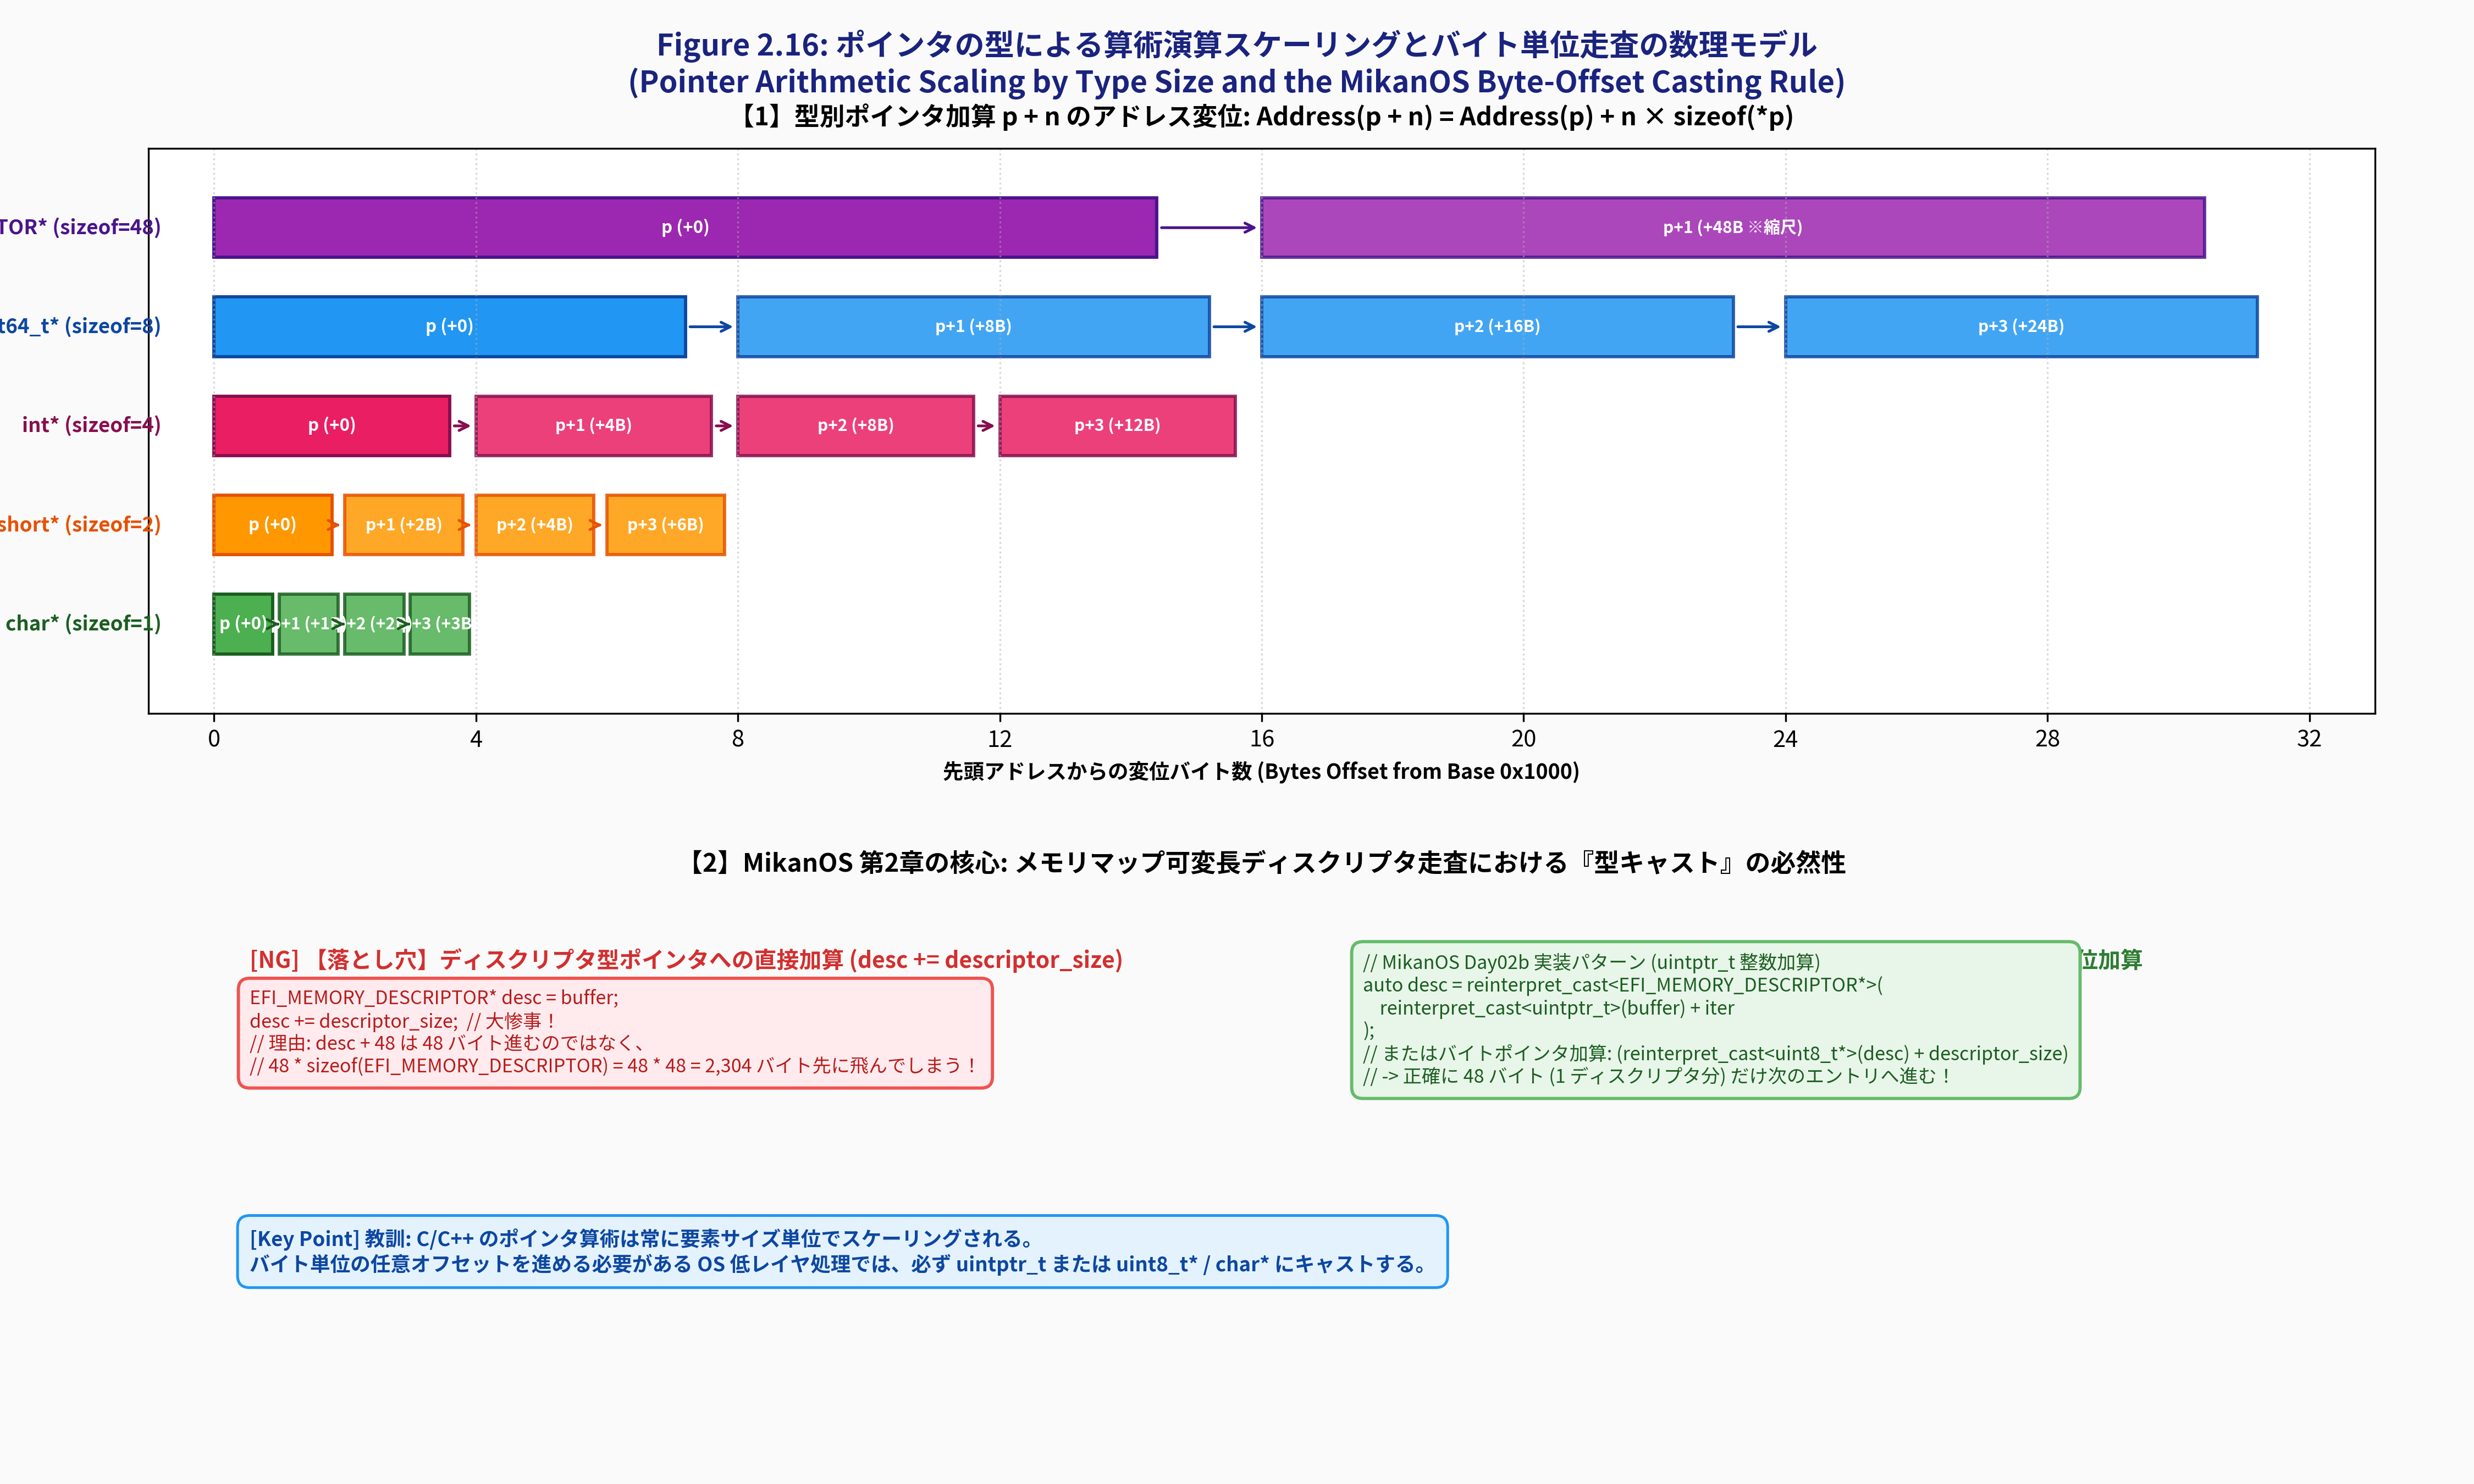

In [3]:
# 高解像度図版 Figure 2.16 の生成とインライン表示
from common import plot_figure_2_16_pointer_arithmetic_scaling
from IPython.display import Image, display

fig2_16_path = "result/fig2_16_pointer_arithmetic_and_type_scaling.png"
plot_figure_2_16_pointer_arithmetic_scaling(fig2_16_path)
display(Image(filename=fig2_16_path, width=950))


## 2.8.8 Python によるポインタ・メモリモデルの対話型シミュレーション

`common/os_sim.py` の `MemoryCellModel` および `PointerModelSimulator` を用いて、
変数配置、ポインタ生成、リトルエンディアンバイト展開、デリファレンスによる値の変更、そしてポインタ算術を対話的に実験・検証します。

In [4]:
from common import MemoryCellModel, PointerModelSimulator

# 1. 仮想メモリ空間の初期化 (ベースアドレス 0x1000, サイズ 8192バイト)
sim = PointerModelSimulator(base_address=0x1000, size=8192)

# 2. 変数の配置 (int val = 0x12345678 at 0x1000)
var_val = sim.allocate_variable("val", "int", 0x12345678, address=0x1000)
print(f"[変数定義] {var_val.name} ({var_val.type_name}, {var_val.size}B) at 0x{var_val.address:04X} = 0x{var_val.value:08X}")

# 3. ポインタ変数の作成 (int* ptr = &val at 0x2000)
ptr = sim.create_pointer("ptr", "val", ptr_address=0x2000)
print(f"[ポインタ定義] {ptr.name} (sizeof={ptr.pointer_size}B) at 0x{ptr.pointer_addr:04X} -> 指し先 0x{ptr.target_addr:04X}")

# 4. リトルエンディアンバイト配列の検査
bytes_val = sim.memory.read_bytes(0x1000, 4)
print("val のメモリ生バイト (0x1000):", [f"0x{b:02X}" for b in bytes_val], "(LSB: 0x78 が先頭)")
bytes_ptr = sim.memory.read_bytes(0x2000, 8)
print("ptr のメモリ生バイト (0x2000):", [f"0x{b:02X}" for b in bytes_ptr], "(64-bit 0x1000 の格納)")

# 5. デリファレンスによる読み取りと書き込み
print(f"デリファレンス *ptr による読み取り: 0x{sim.dereference('ptr'):08X}")
sim.assign_via_pointer("ptr", 0x55AA55AA)
print(f"*ptr = 0x55AA55AA 書き込み後の val の値: 0x{sim.variables['val'].value:08X}")
assert sim.memory.read_int32(0x1000) == 0x55AA55AA

# 6. ポインタ算術ステップ検証
print("\n[ポインタ算術ステップ検証]")
for delta in [0, 1, 2, 3]:
    next_addr = sim.pointer_arithmetic("ptr", delta)
    print(f"  ptr + {delta} -> 0x{next_addr:04X} (変位 +{next_addr - 0x1000} バイト)")
    assert next_addr == 0x1000 + delta * 4
print("全 Python シミュレーション検証がパスしました！")


[変数定義] val (int, 4B) at 0x1000 = 0x12345678
[ポインタ定義] ptr (sizeof=8B) at 0x2000 -> 指し先 0x1000
val のメモリ生バイト (0x1000): ['0x78', '0x56', '0x34', '0x12'] (LSB: 0x78 が先頭)
ptr のメモリ生バイト (0x2000): ['0x00', '0x10', '0x00', '0x00', '0x00', '0x00', '0x00', '0x00'] (64-bit 0x1000 の格納)
デリファレンス *ptr による読み取り: 0x12345678
*ptr = 0x55AA55AA 書き込み後の val の値: 0x55AA55AA

[ポインタ算術ステップ検証]
  ptr + 0 -> 0x1000 (変位 +0 バイト)
  ptr + 1 -> 0x1004 (変位 +4 バイト)
  ptr + 2 -> 0x1008 (変位 +8 バイト)
  ptr + 3 -> 0x100C (変位 +12 バイト)
全 Python シミュレーション検証がパスしました！


## 2.8.9 C++20 ホスト側ポインタ検証コードの対話型コンパイル＆実行

ホスト側の C++20 コンパイラ（`g++ -std=c++20`）を用いて、
64ビットポインタサイズ不変性、リトルエンディアン、デリファレンス、および MikanOS メモリマップ走査のキャスト処理をスタンドアロン検証バイナリとしてコンパイル・実行します。

In [5]:
# C++20 スタンドアロン検証コードのビルドと実行
import subprocess

compile_cmd = [
    "g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "-Wpedantic",
    "../src/ch02/pointer_basics_sim.cpp", "-o", "/tmp/ch02_pointer_basics_sim"
]
print("C++20 検証バイナリをコンパイル中...")
comp_res = subprocess.run(compile_cmd, capture_output=True, text=True)
if comp_res.returncode != 0:
    print("コンパイルエラー:", comp_res.stderr)
else:
    print("コンパイル成功！実行出力を表示します:\n")
    run_res = subprocess.run(["/tmp/ch02_pointer_basics_sim"], capture_output=True, text=True)
    print(run_res.stdout)


C++20 検証バイナリをコンパイル中...


コンパイル成功！実行出力を表示します:

  MikanOS Ch 2.8: Pointer & Addressing Verification Engine

[Verification Report]
  1. 64-bit Pointer Size Invariance (sizeof(T*) == 8): PASSED
  2. Address (&) and Dereference (*) Read:            PASSED
  3. Dereference (*) Store / Mutation:                PASSED
  4. Little-Endian Byte Order Storage:                PASSED
  5. Pointer Arithmetic Stride Scaling:               PASSED
  6. UEFI Memory Map Traversal Casting (uintptr_t):   PASSED
  7. VRAM Direct Frame Buffer Access Emulation:       PASSED

>>> ALL 7 POINTER ARCHITECTURE VERIFICATIONS PASSED! <<<

[Pointer Math Demonstration]
  Base Address: 0x7ffd2b146a10
  char*     p + 1 -> offset +1 bytes
  short*    p + 1 -> offset +2 bytes
  int*      p + 1 -> offset +4 bytes
  uint64_t* p + 1 -> offset +8 bytes



## 2.8.10 OS 自作におけるポインタの真価（VRAM・MMIO・カーネルエントリへの布石）

### 1. 次章（第3章）への架け橋: VRAM への直接ピクセル描画
第3章「画面表示の練習とブートローダ」では、UEFI の GOP (*Graphics Output Protocol*) から取得したフレームバッファの物理アドレス（例: `0xE0000000`）に対して、以下のようにポインタ経由で直接色データを書き込みます。

```cpp
// フレームバッファの先頭アドレスを uint8_t* にキャスト
uint8_t* frame_buffer = reinterpret_cast<uint8_t*>(fb_base);

// 座標 (x, y) にピクセルを描画する際のオフセット計算
// 1ピクセルあたり 4バイト (32bpp RGB)
size_t pixel_index = (y * horizontal_resolution + x) * 4;
frame_buffer[pixel_index + 0] = 255; // Red
frame_buffer[pixel_index + 1] = 255; // Green
frame_buffer[pixel_index + 2] = 255; // Blue
```
このように、OS カーネルでは「ハードウェアが要求する物理番地をポインタにキャストして直接叩く」ことがグラフィックス描画の根本原理です。

### 2. カーネル呼び出し（関数ポインタへのキャスト）
ブートローダがメモリの `0x100000` にロードしたカーネルの先頭コードを呼び出す処理も、ポインタのキャストです。

```cpp
// カーネルエントリポイントの型定義 (引数にフレームバッファ情報)
typedef void EntryPointType(const FrameBufferConfig*);

// アドレス 0x100000 を関数ポインタにキャストしてジャンプ
auto entry_point = reinterpret_cast<EntryPointType*>(0x100000);
entry_point(&config); // これでブートローダから自作カーネルへ制御が移る！
```

### 3. ヌルポインタ（`nullptr`）とページフォールト例外（#PF）
ポインタにアドレス `0x0`（ゼロ）を代入したものを **ヌルポインタ（Null Pointer: `nullptr`）** と呼び、「現在どこも指していない無効な状態」を表現する番兵値として用いられます。

OS のページング機構（第19章）では、物理番地 `0x0` 付近はわざと未マップ（Page Not Present）にしておくのが現代OSの常識です。
これにより、バグでヌルポインタをデリファレンス（`*nullptr`）した瞬間に、CPUが直ちに **ページフォールト例外（Page Fault: `#PF`, ベクタ 14）** を発生させ、OSが問題のプロセスを即座にクラッシュ・強制終了させてシステム全体の破損を防ぐことができます。

## 2.8.11 理解度確認クイズ（自己採点形式）

2.8節で学んだ 64ビットポインタの性質、リトルエンディアン、ポインタ算術、キャスト規則について、
穴埋め変数を完成させて下のセルを実行し、自己採点を行ってください。

In [6]:
# === 2.8 理解度確認クイズ ===
# 以下の変数の値を、解説の内容に基づいて正しく設定してください。

# Q1: 64ビット (x86-64) アーキテクチャにおいて、ポインタ変数自身のサイズ (sizeof(T*)) は何バイトでしょうか？
ANS_POINTER_SIZE_BYTES = 8

# Q2: 32ビット整数 0xAABBCCDD をリトルエンディアンでメモリのアドレス 0x1000 から格納したとき、
#     最も若い先頭番地 0x1000 に格納される 1 バイトの値は 16進数で何でしょうか？ (例: 0xAA または 0xDD)
ANS_LITTLE_ENDIAN_BYTE_0 = 0xDD

# Q3: int* 型のポインタ p (sizeof(int) == 4) がアドレス 0x2000 を指しているとき、
#     ポインタ加算 p + 3 が指すメモリアドレスは 16進数で何番地でしょうか？
ANS_POINTER_ADD_ADDRESS = 0x200C  # 0x2000 + 3 * 4 = 0x2000 + 12 = 0x200C

# Q4: MikanOS において、1エントリ 48 バイトの EFI_MEMORY_DESCRIPTOR 配列をバイト単位で安全に走査するために、
#     バッファポインタをどの型にキャストしてオフセット iter を加算したでしょうか？ (文字列で選択)
#     選択肢: "int*", "uintptr_t", "double*", "void"
ANS_SAFE_STRIDE_TYPE = "uintptr_t"

# ------------------------------------------------------------
# 検証コード (assert による自己採点)
assert ANS_POINTER_SIZE_BYTES == 8, "Q1 不正解: x86-64 ではポインタは常に 8 バイトです"
assert ANS_LITTLE_ENDIAN_BYTE_0 == 0xDD, "Q2 不正解: リトルエンディアンでは最下位バイト (LSB: 0xDD) が先頭に格納されます"
assert ANS_POINTER_ADD_ADDRESS == 0x200C, "Q3 不正解: p + 3 は 0x2000 + 3 * 4 = 0x200C 番地です"
assert ANS_SAFE_STRIDE_TYPE == "uintptr_t", "Q4 不正解: バイト単位加算には整数型 uintptr_t または uint8_t* を使用します"

print("おめでとうございます！2.8節 理解度確認クイズ 4問すべてに正解しました！")


おめでとうございます！2.8節 理解度確認クイズ 4問すべてに正解しました！
